In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
import seaborn as sns
import random
from pathlib import Path
import datetime
import joblib
import shutil
from scipy.ndimage import gaussian_filter
from scipy.signal import find_peaks
from statistics import mean
# from sklearn.metrics.pairwise import cosine_similarity

sys.path.insert(0, "../../Python/cellular_cycle")
from model_fxns import get_traj, plot_traj, restructProt, cosine_similarity, get_cos_similarities


# locations of previously generated simulation data
SAVE_DIR = Path('~/ECM_mod_output').expanduser()
SAVE_DIR.mkdir(exist_ok=True)   # create the directory if it doesn't exist  

SAVEFILES = True
OVERWRITE = False

EMBED_DIR = Path('../../Data','UMAP_embedding_ode') # location of saved embedding files for each condition

SET_JPARAM = False # Set the parameters for the simulation

sys_type = sys.platform

output_from = 1 # 1: original, 3: 03_ECM_model_output.ipynb, 4: 04_Stoch_sims_for_UMAP.ipynb

if sys_type == 'darwin':
    sys_name = 'mac'
elif sys_type == 'win32': 
    sys_name = 'win'
elif sys_type == 'linux': 
    sys_name = 'linux'

In [2]:
rcParams.update({'figure.autolayout': True})

In [3]:
if output_from == 1:
    embed_source = 'orig'
else:
    embed_source = f'from_0{output_from}'

all_embed_odes = joblib.load(Path(SAVE_DIR, f'all_embedding_ode_conds_{sys_name}_{embed_source}.sav'))
all_embed_odes.shape

(20000, 2)

In [4]:
all_embed_stoch = joblib.load(Path(SAVE_DIR, f'all_embedding_stoch_conds_{sys_name}_{embed_source}.sav')) # output of 05_UMAP_of_stoch_sims.ipynb (experimental conds)
all_embed_stoch.shape

(399930, 2)

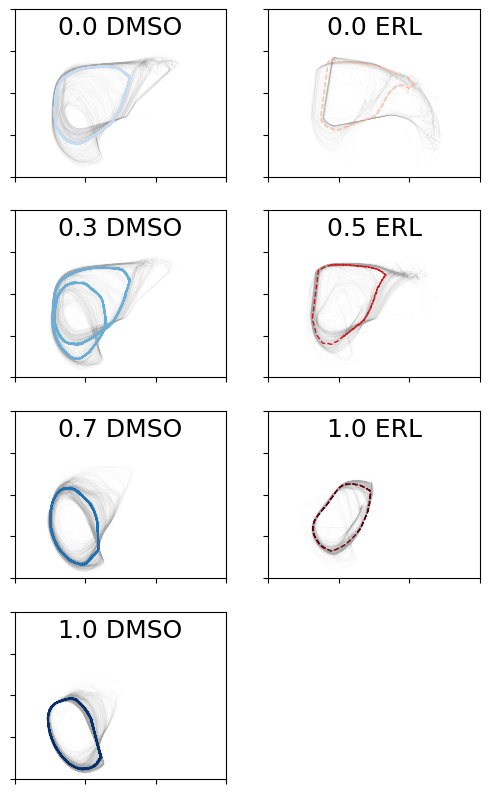

In [108]:
fig = plt.figure(figsize=(6,10))
vals = [0, 5, 1, 6, 3, 7, 4]
color_ind = [1, 1, 2, 3, 3, 4, 4]
titles = ['0.0 DMSO', '0.0 ERL', '0.3 DMSO', '0.5 ERL', '0.7 DMSO', '1.0 ERL', '1.0 DMSO']
fign = 1

for n in vals:
    plt.subplot(4,2,fign)
    n1 = n + 1
    trk_len = int(len(embedding_all_prot)/len(filenames_sp))
    trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))
    plt.plot(embedding_all_prot[n*trk_len:n1*trk_len,0], embedding_all_prot[n*trk_len:n1*trk_len,1], lw=0.01, alpha=0.7, c='gray')
    if (fign % 2) == 0:
        plt.plot(embedding_all_prot_ode[n*trk_len_ode:n*trk_len_ode+100,0], embedding_all_prot_ode[n*trk_len_ode:n*trk_len_ode+100,1], 
                 ls='--', lw=1, alpha=1, color=colors_red[color_ind[fign-1]])
    else:
        plt.plot(embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,0], embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,1], 
                 lw=1, alpha=1, color=colors_blue[color_ind[fign-1]])


    
    plt.xlim(-10,20)
    plt.ylim(0, 20)
    plt.rcParams['axes.titley'] = 1.0
    plt.rcParams['axes.titlepad'] = -18
    plt.title(titles[fign-1])

    ax = plt.gca()
    ax.yaxis.set_tick_params(labelleft=False)
    ax.xaxis.set_tick_params(labelleft=False)

    fign += 1
    